We want to verify integrity of dipolar matrix elements. For this, we will compute dielectric permittivity from ground state dipolar matrix elements. 

# Accessing dipolar matrix elements

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from octopus_slabs.Libs.libString import GetEigenValue, ReadDipolarMatrixElements
import octopus_slabs.Libs.libAtomicUnits as lat
from scipy.constants import physical_constants
from scipy.constants import epsilon_0, hbar, h

In [2]:
%cd "/nfsfileshare/octopus.data/03-Si/2022-1-23-Si-1x1x1-k-16x16x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-ME-K_Gamma_X-1000pts-redo2/"
%pwd

/nfsfileshare/octopus.data/03-Si/2022-1-23-Si-1x1x1-k-16x16x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-ME-K_Gamma_X-1000pts-redo2


'/nfsfileshare/octopus.data/03-Si/2022-1-23-Si-1x1x1-k-16x16x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-ME-K_Gamma_X-1000pts-redo2'

In [3]:
eigen_H=GetEigenValue(1, NumberOfEigenValues=12)
eigen_eV=lat.Hartree_Energy*eigen_H

Info: Construction of the eigen-values matrix.
Pattern of interest: "#k ="
[libString: GetEigenValue(): ]#k =   1, k = (  0.000000,  0.000000,  0.000000)

[libString: GetEigenValue(): ]['   1   --    -0.289865       2.000000\n', '   2   --     0.147731       2.000000\n', '   3   --     0.147731       2.000000\n', '   4   --     0.147731       2.000000\n', '   5   --     0.241792       0.000000\n', '   6   --     0.241792       0.000000\n', '   7   --     0.241792       0.000000\n', '   8   --     0.267086       0.000000\n', '   9   --     0.431610       0.000000\n', '  10   --     0.432578       0.000000\n', '  11   --     0.432578       0.000000\n', '  12   --     0.558386       0.000000\n']


In [4]:
eigen_eV

array([-7.88762841,  4.01996527,  4.01996527,  4.01996527,  6.57949545,
        6.57949545,  6.57949545,  7.26778025, 11.74470632, 11.77104694,
       11.77104694, 15.19445699])

In [5]:
d, size=ReadDipolarMatrixElements(4, 8, ["static/ks_me_dipole.k1_x"])

** Info: opening file static/ks_me_dipole.k1_x


Dipolar matrix elements are now available in $d$ matrix. 

In [6]:
d

array([[0.00000000e+00, 3.83339100e-06, 6.76995000e-07, 2.84272700e-06,
        1.58056836e-01, 2.68128335e-02, 2.15538996e-01, 1.50470000e-08,
        4.00000000e-12, 1.22000000e-10, 3.58400000e-09, 2.30170700e-06],
       [3.83339100e-06, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        2.30572494e+00, 1.09208389e+00, 1.55497785e+00, 3.71064811e+00,
        8.66644200e-06, 3.08753578e-01, 1.28492804e+00, 7.14312100e-06],
       [6.76995000e-07, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        4.56253796e-01, 4.76887804e+00, 9.27823085e-01, 6.55322858e-01,
        1.53054000e-06, 5.45374284e-02, 2.26923496e-01, 3.75500200e-06],
       [2.84272700e-06, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        3.21808861e+00, 3.36968013e-01, 2.31796760e+00, 2.75158376e+00,
        6.42676100e-06, 2.28958503e-01, 9.52842070e-01, 8.85938500e-06],
       [1.58056836e-01, 2.30572494e+00, 4.56253796e-01, 3.21808861e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 7.29

# Plot its contents

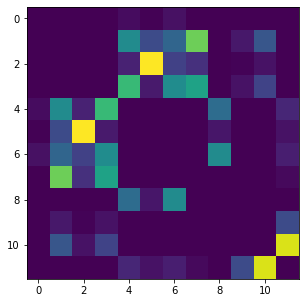

In [7]:
plt.figure(figsize=(10,5))
plt.imshow(d)
plt.show()

# Deducing dielectric permittivity at $\Gamma$

## Density of electrons

In [8]:
a0=physical_constants['Bohr radius'][0]
print(a0)

5.29177210903e-11


In [9]:
volume_b3=270.2564
volume_m3=np.power(
    np.multiply(
        np.power(volume_b3, 1./3.),
        a0)
        ,3)
N=4./volume_b3
print(N)


0.014800759574981389


In [10]:
eigen_t=np.array(eigen_H)
print(eigen_t)
print(size)

[-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
  0.267086  0.43161   0.432578  0.432578  0.558386]
12


## Build the transition matrix

In [11]:
omega1=np.tile(eigen_t, (size,1))

print(omega1)
print(np.shape(omega1))

[[-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]
 [-0.289865  0.147731  0.147731  0.147731  0.241792  0.241792  0.241792
   0.267086  0.43161   0.432578  0.432578  0.558386]


In [12]:
omega2=np.transpose(np.tile(eigen_t, (size,1)))
print(omega2)
print(np.shape(omega2))

[[-0.289865 -0.289865 -0.289865 -0.289865 -0.289865 -0.289865 -0.289865
  -0.289865 -0.289865 -0.289865 -0.289865 -0.289865]
 [ 0.147731  0.147731  0.147731  0.147731  0.147731  0.147731  0.147731
   0.147731  0.147731  0.147731  0.147731  0.147731]
 [ 0.147731  0.147731  0.147731  0.147731  0.147731  0.147731  0.147731
   0.147731  0.147731  0.147731  0.147731  0.147731]
 [ 0.147731  0.147731  0.147731  0.147731  0.147731  0.147731  0.147731
   0.147731  0.147731  0.147731  0.147731  0.147731]
 [ 0.241792  0.241792  0.241792  0.241792  0.241792  0.241792  0.241792
   0.241792  0.241792  0.241792  0.241792  0.241792]
 [ 0.241792  0.241792  0.241792  0.241792  0.241792  0.241792  0.241792
   0.241792  0.241792  0.241792  0.241792  0.241792]
 [ 0.241792  0.241792  0.241792  0.241792  0.241792  0.241792  0.241792
   0.241792  0.241792  0.241792  0.241792  0.241792]
 [ 0.267086  0.267086  0.267086  0.267086  0.267086  0.267086  0.267086
   0.267086  0.267086  0.267086  0.267086  0.267086]


In [13]:
omega_mn=omega1-omega2 #distance between every possible levels at $\Gamma$, computed frmo eigenvalues
print(omega_mn)

[[ 0.        0.437596  0.437596  0.437596  0.531657  0.531657  0.531657
   0.556951  0.721475  0.722443  0.722443  0.848251]
 [-0.437596  0.        0.        0.        0.094061  0.094061  0.094061
   0.119355  0.283879  0.284847  0.284847  0.410655]
 [-0.437596  0.        0.        0.        0.094061  0.094061  0.094061
   0.119355  0.283879  0.284847  0.284847  0.410655]
 [-0.437596  0.        0.        0.        0.094061  0.094061  0.094061
   0.119355  0.283879  0.284847  0.284847  0.410655]
 [-0.531657 -0.094061 -0.094061 -0.094061  0.        0.        0.
   0.025294  0.189818  0.190786  0.190786  0.316594]
 [-0.531657 -0.094061 -0.094061 -0.094061  0.        0.        0.
   0.025294  0.189818  0.190786  0.190786  0.316594]
 [-0.531657 -0.094061 -0.094061 -0.094061  0.        0.        0.
   0.025294  0.189818  0.190786  0.190786  0.316594]
 [-0.556951 -0.119355 -0.119355 -0.119355 -0.025294 -0.025294 -0.025294
   0.        0.164524  0.165492  0.165492  0.2913  ]
 [-0.721475 -0.283

In [14]:
dSquared=np.power(d,2)
print(np.shape(dSquared))

(12, 12)


In [15]:
from scipy.constants import pi,c,e
wavelength=800e-9
omega=2*pi*c/wavelength; 
omega_H=hbar*omega/lat.Hartree_Energy/e
print(omega, "Hz")
print(omega_H, "Hartree")

2354564459136066.5 Hz
0.05695419113439939 Hartree


(12, 12)


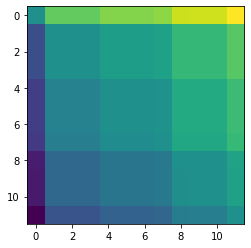

In [16]:
print(np.shape(omega_mn))
plt.figure()
plt.imshow(omega_mn*lat.Hartree_Energy)
# plt.legend(loc="best")
plt.show()

In [17]:
# np.divide(dSquared,omega_mn-omega) ready

## Density matrix preparation

In [18]:
"""
rng = np.random.default_rng()
density2=rng.random((size,size))
density1=np.zeros((size, size))
print(density2)
"""

'\nrng = np.random.default_rng()\ndensity2=rng.random((size,size))\ndensity1=np.zeros((size, size))\nprint(density2)\n'

In [19]:
density1=np.zeros((size, size)) #rho_mm=0
density2=density1 #rho_nn=0
#all states from valence bands are populated
print(density1)
print(density2)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


## Occupation: Fermi-Dirac distribution

In [95]:
# Returns the population as function of energy E
#@param Te: Fermion energy
#@param Ef: Fermi energy
#@param E: energy of interest
def FermiDirac(E, Te=0, Ef=0):
    import numpy as np
    from scipy.constants import physical_constants
    kb=physical_constants['Boltzmann constant']
    return np.divide(1.,1.+np.exp(np.divide(np.add(Ef,-1*E),kb*Te)))

In [102]:
FermiDirac(1,Te=300)

TypeError: ufunc 'true_divide' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

## Complete formula

In [20]:
gamma=1

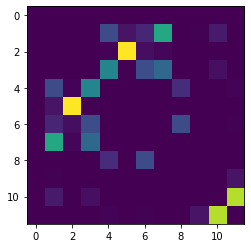

In [21]:
plt.figure()
plt.imshow(np.abs(np.divide(dSquared,omega_mn-omega-gamma*1j)))
plt.show()

In [22]:
terms=np.multiply(density1,np.divide(dSquared,omega_mn-omega-gamma*1j))
print(terms)
print(np.shape(terms))

[[ 0.0000000e+00-0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j]
 [-0.0000000e+00+0.00000000e+00j  0.0000000e+00-0.00000000e+00j
   0.0000000e+00-0.00000000e+00j  0.0000000e+00-0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -0.0000000e+00+0.00000000e+00j]
 [-0.0000000e+00+0.00000000e+00j  0.0000000e+00-0.00000000e+00j
   0.0000000e+00-0.00000000e+00j  0.0000000e+00-0.00000000e+00j
  -0.0000000e+00+0.00000000e+00j -9.6587705e-15+4.10214741e-30j
  -0.0000000e+00+0.00000000e+00j -0.00

Formula (3.5.15) from Boyd is given by $\varepsilon_{ij}^{(1)}=1+\chi_{ij}^{(1)}\left(\omega\right)=1+\frac{N}{\varepsilon_{0}\hbar}\sum_{nm}\left(\rho_{mm}-\rho_{nn}\right)\frac{d_{mn}d_{nm}}{\left(\omega_{nm}-\omega\right)-i\gamma_{nm}}$

In [23]:
epsilon0_Hartree=1./4./pi
epsilon=1+N/epsilon0_Hartree * np.sum(terms)
print(epsilon)

(0.9999999999999982+7.629659047475949e-31j)


## Simplified for ground state

This formula can be simplified into Eq. (3.5.20), assuming an excitation from the ground state, as follows
$\varepsilon_{ij}^{(1)}=1+\chi_{ij}^{(1)}\left(\omega\right)=1+\frac{N}{\varepsilon_{0}\hbar}\sum_{n}\left[\frac{d_{gn}d_{ng}}{\left(\omega_{ng}-\omega\right)-i\gamma_{nm}}+\frac{d_{ng}d_{gn}}{\left(\omega_{ng}+\omega\right)+i\gamma_{ng}}\right]$

In [24]:
terms1=np.divide(dSquared,omega_mn-omega-gamma*1j)
terms2=np.divide(dSquared,omega_mn+omega+gamma*1j)

In [27]:
epsilon=1+N/epsilon0_Hartree * np.sum(terms1+terms2)
print(epsilon)

(1+0j)


I understand that populations should be computed using TDDFT linear response, but if filling the populations in diagonal elements, these electrons are not eligible for promotion. However, if putting them in the non-diagonal terms, they are eligible for transition, and then count for the dielectric permittivity. 

In [73]:
#@Z: number of valence electrons in ground state
#@param volume of primitive cell in Bohr**3
#@param eigen_t: vector of eigenvalues
#@param dipole: matrix of dipolar couplings between eigenvalues
#@param omega is spectrum (eV) where we need dielectric permittivity
def KuboGreenwood(Z, volume, eigen_t, dipole, omega_eV, gamma=0):
    import octopus_slabs.Libs.libAtomicUnits as lat
    from scipy.constants import physical_constants
    from scipy.constants import epsilon_0, hbar, h
    
    epsilon=[]
    
    N=Z/volume #number of valence electrons per Bohr**3
    
    size=len(eigen_t)
    assert(len(dipole)==size) #checks that dipolar matrix elements are well shaped in respect of eigenvalues
    
    omega1=np.tile(eigen_t, (size,1))
    omega2=np.transpose(np.tile(eigen_t, (size,1)))
    omega_mn=omega1-omega2 #all possible transitions
    
    dSquared=np.power(dipole,2)
    
    for omega_local in omega_eV:
        omega_H=np.divide(omega_local, lat.Hartree_Energy)
    
        terms1=np.divide(dSquared,omega_mn-omega_local-gamma*1j)
        terms2=np.divide(dSquared,omega_mn+omega_local+gamma*1j)
        
        epsilon.append(1+N/epsilon0_Hartree * np.sum(terms1+terms2))
    return epsilon

In [77]:
omega=np.arange(0.1,10.1, 0.01)
print(omega)

[ 0.1   0.11  0.12  0.13  0.14  0.15  0.16  0.17  0.18  0.19  0.2   0.21
  0.22  0.23  0.24  0.25  0.26  0.27  0.28  0.29  0.3   0.31  0.32  0.33
  0.34  0.35  0.36  0.37  0.38  0.39  0.4   0.41  0.42  0.43  0.44  0.45
  0.46  0.47  0.48  0.49  0.5   0.51  0.52  0.53  0.54  0.55  0.56  0.57
  0.58  0.59  0.6   0.61  0.62  0.63  0.64  0.65  0.66  0.67  0.68  0.69
  0.7   0.71  0.72  0.73  0.74  0.75  0.76  0.77  0.78  0.79  0.8   0.81
  0.82  0.83  0.84  0.85  0.86  0.87  0.88  0.89  0.9   0.91  0.92  0.93
  0.94  0.95  0.96  0.97  0.98  0.99  1.    1.01  1.02  1.03  1.04  1.05
  1.06  1.07  1.08  1.09  1.1   1.11  1.12  1.13  1.14  1.15  1.16  1.17
  1.18  1.19  1.2   1.21  1.22  1.23  1.24  1.25  1.26  1.27  1.28  1.29
  1.3   1.31  1.32  1.33  1.34  1.35  1.36  1.37  1.38  1.39  1.4   1.41
  1.42  1.43  1.44  1.45  1.46  1.47  1.48  1.49  1.5   1.51  1.52  1.53
  1.54  1.55  1.56  1.57  1.58  1.59  1.6   1.61  1.62  1.63  1.64  1.65
  1.66  1.67  1.68  1.69  1.7   1.71  1.72  1.73  1

In [78]:
epsilon=KuboGreenwood(4, volume_b3, eigen_t, d, omega)
print(epsilon)

[(0.9999999999997463+0j), (1.0000000000000422+0j), (1+0j), (1+0j), (1.0000000000000422+0j), (1+0j), (0.9999999999999895+0j), (1+0j), (0.9999999999999908+0j), (1.0000000000013534+0j), (0.9999999999999682+0j), (1.0000000000000107+0j), (0.9999999999999895+0j), (0.9999999999999947+0j), (1.0000000000000107+0j), (1.0000000000000053+0j), (1.0000000000000107+0j), (0.9999999999999921+0j), (0.9999999999999895+0j), (0.9999999999999789+0j), (1+0j), (0.9999999999999947+0j), (1+0j), (1+0j), (1+0j), (0.9999999999999973+0j), (1+0j), (1.0000000000000027+0j), (0.9999999999999973+0j), (1.0000000000000027+0j), (0.9999999999999973+0j), (1.0000000000000027+0j), (1+0j), (1+0j), (0.9999999999999987+0j), (0.9999999999999973+0j), (0.9999999999999987+0j), (1.0000000000000013+0j), (1.0000000000000027+0j), (0.9999999999999973+0j), (1.0000000000000013+0j), (1+0j), (1.0000000000000013+0j), (1.0000000000000007+0j), (1+0j), (0.9999999999999987+0j), (1+0j), (1.0000000000000013+0j), (1+0j), (0.9999999999999993+0j), (0.9

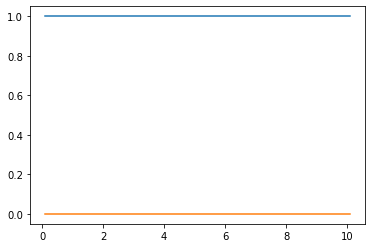

In [79]:
plt.figure()
plt.plot(omega,np.real(epsilon))
plt.plot(omega,np.imag(epsilon))
plt.show()

# Kubo-Greenwood for Floquet states

In principle, applying Kubo-Greenwood to Floquet should work, since Floquet states never really cross. They anti-cross, i.e., avoid each others. Check paper of Sentef in Sci. Adv. 

# Checking continuity of dipolar matrix elements

Reading dipolar matrix elements as function of k-point-path. Checking continuity of one element on the path $K-\Gamma-X$. 